# TextureGuard AI — Artificial Texture Defect Classification

Nama : Evan Rafa Radya Alifian

NIM : 240411100063

Kelas : Machine Learning - E

---

**TextureGuard AI** adalah proyek pembelajaran mesin untuk mengklasifikasikan citra tekstur buatan dengan menggunakan ekstraksi fitur yang dirancang secara manual (*handcrafted feature extraction*) serta pembelajaran mesin otomatis (*Automated Machine Learning* atau AutoML).

Proyek ini menggunakan **kumpulan data DAGM 2007**, **PyFeats** untuk ekstraksi fitur tekstur dengan metode **Local Binary Pattern (LBP)**, serta **PyCaret** untuk membandingkan dan mengevaluasi model klasifikasi pembelajaran mesin.

## Sumber Dataset

- **Nama dataset**: DAGM 2007 — *Weakly Supervised Learning for Industrial Optical Inspection*
- **Penyedia**: DAGM (German Association for Pattern Recognition) bersama HCI, Universitas Heidelberg
- **Tautan unduhan**: https://conferences.mpi-inf.mpg.de/dagm/2007/prizes.html
- **Berkas yang digunakan**: `Class1.zip` s.d. `Class6.zip`, diekstrak ke `datasets/raw/Class1` ... `datasets/raw/Class6`
- **Karakteristik**: citra tekstur buatan (*artificial texture*) grayscale 8-bit berukuran 512 × 512 piksel. Tiap kelas memiliki latar tekstur dengan karakter berbeda.
- **Jumlah data**: 6 kelas × 1000 citra = 6000 citra (seimbang)

**Rumusan tugas klasifikasi**: *multikelas* (6 kelas). Label diambil dari nama folder (`Class1` ... `Class6`).

# TextureGuard AI — Image Preprocessing

Tahap ini bertujuan untuk memeriksa struktur dataset DAGM 2007,
memvalidasi citra, dan menyiapkan gambar untuk ekstraksi fitur tekstur.

## Periksa struktur folder dan jumlah gambar

In [25]:
from pathlib import Path
from collections import Counter

DATASET_DIR = Path("../datasets/raw")

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Folder tidak ditemukan: {DATASET_DIR.resolve()}")

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

print("Lokasi dataset:", DATASET_DIR.resolve())
print("\nStruktur folder kelas:\n")

for folder in sorted(DATASET_DIR.iterdir()):
    if folder.is_dir():
        files = [p for p in folder.rglob("*") if p.is_file()]

        images = [p for p in files if p.suffix.lower() in IMAGE_EXTENSIONS]

        print(
            f"{folder.name}: "
            f"{len(images)} gambar, "
            f"{len(files) - len(images)} file lain"
        )

Lokasi dataset: C:\Users\acer\Desktop\evanalifian\textureguard-ai-dagm2007\datasets\raw

Struktur folder kelas:

Class1: 1000 gambar, 0 file lain
Class2: 1000 gambar, 0 file lain
Class3: 1000 gambar, 0 file lain
Class4: 1000 gambar, 0 file lain
Class5: 1000 gambar, 0 file lain
Class6: 1000 gambar, 0 file lain


#### Penjelasan: cek struktur folder dan jumlah gambar

**Tujuan.** Memastikan dataset ada di tempat yang benar dan lengkap sebelum diolah.

**Proses.** Kode membuka folder `datasets/raw`, lalu untuk setiap sub-folder (satu folder = satu kelas) menghitung berapa file yang merupakan gambar (`.png`, `.jpg`, dst.) dan berapa yang bukan. Jika folder tidak ada, kode berhenti dengan pesan error yang jelas.

**Hasil.** Terdapat 6 kelas (`Class1` sampai `Class6`), masing-masing **1000 gambar** dan **0 file lain**.

**Artinya.** Dataset lengkap dan **seimbang** (jumlah tiap kelas sama), jadi model tidak akan condong ke kelas tertentu hanya karena kelas itu lebih banyak.

In [26]:
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_files = [
  path
  for path in DATASET_DIR.rglob("*")
  if path.is_file() and path.suffix.lower() in image_extensions
]

extension_counts = Counter(path.suffix.lower() for path in image_files)

print("Total file gambar:", len(image_files))
print("\nJumlah gambar berdasarkan ekstensi:")

for extension, count in sorted(extension_counts.items()):
  print(f"{extension}: {count}")

print("\nContoh file gambar:")
for path in image_files[:10]:
  print(path.relative_to(DATASET_DIR))

Total file gambar: 6000

Jumlah gambar berdasarkan ekstensi:
.png: 6000

Contoh file gambar:
Class1\1.png
Class1\10.png
Class1\100.png
Class1\1000.png
Class1\101.png
Class1\102.png
Class1\103.png
Class1\104.png
Class1\105.png
Class1\106.png


#### Penjelasan: hitung total gambar per jenis ekstensi

**Tujuan.** Memastikan semua gambar berformat sama dan melihat contoh nama file.

**Proses.** Kode mencari semua file gambar di seluruh sub-folder, lalu menghitung berapa banyak untuk tiap ekstensi.

**Hasil.** Total **6000 gambar**, seluruhnya `.png`. Contoh namanya `Class1\1.png`, `Class1\10.png`, `Class1\100.png`, ...

**Artinya.** Semua gambar berformat seragam. Urutan nama (`1, 10, 100, 1000, 101, ...`) adalah urutan abjad, bukan urutan angka. Ini tidak masalah, karena urutan tidak mempengaruhi hasil pemodelan.

## Tampilkan contoh gambar dari setiap kelas

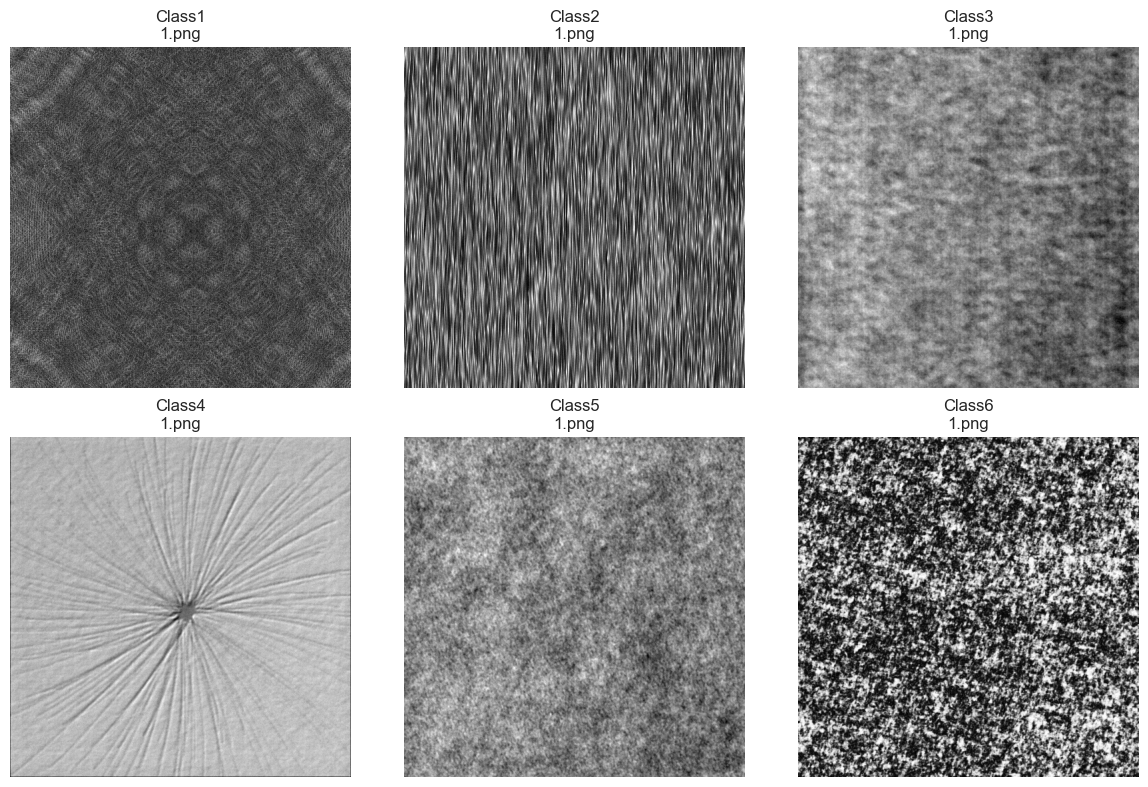

In [27]:
import cv2
import matplotlib.pyplot as plt
import math

class_folders = sorted(p for p in DATASET_DIR.iterdir() if p.is_dir())

samples = []

for folder in class_folders:
    images = sorted(
        p
        for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    if images:
        samples.append((folder.name, images[0]))

if not samples:
    raise ValueError("Tidak ditemukan gambar dalam folder kelas.")

columns = 3
rows = math.ceil(len(samples) / columns)

fig, axes = plt.subplots(rows, columns, figsize=(12, 4 * rows), squeeze=False)

for ax in axes.flat:
    ax.axis("off")

for ax, (class_name, image_path) in zip(axes.flat, samples):
    image = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)

    if image is None:
        ax.set_title(f"{class_name}: gagal dibaca")
        continue

    if image.ndim == 2:
        ax.imshow(image, cmap="gray")
    elif image.ndim == 3 and image.shape[2] == 3:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    elif image.ndim == 3 and image.shape[2] == 4:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGRA2RGBA))
    else:
        ax.text(0.5, 0.5, f"Shape: {image.shape}", ha="center")

    ax.set_title(f"{class_name}\n{image_path.name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Penjelasan: tampilkan satu contoh gambar tiap kelas

**Tujuan.** Melihat langsung seperti apa tekstur tiap kelas.

**Proses.** Untuk setiap kelas, kode mengambil gambar pertama (setelah diurutkan) dan menyimpannya di daftar `samples`, lalu menampilkannya dalam kisi 3 × 2 dengan `matplotlib`. Daftar `samples` dipakai lagi di cell-cell berikutnya.

**Artinya.** Dengan mata saja sudah terlihat bahwa tiap kelas punya "karakter" tekstur berbeda. Inilah yang nanti ditangkap oleh fitur LBP.

## Periksa dimensi, kanal warna, dan tipe data

In [28]:
import pandas as pd

records = []

for folder in class_folders:
    for image_path in folder.rglob("*"):
        if (
            not image_path.is_file()
            or image_path.suffix.lower() not in IMAGE_EXTENSIONS
        ):
            continue

        image = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)

        record = {
            "class": folder.name,
            "filename": image_path.name,
            "path": str(image_path),
            "readable": image is not None,
        }

        if image is not None:
            record["height"] = image.shape[0]
            record["width"] = image.shape[1]
            record["channels"] = 1 if image.ndim == 2 else image.shape[2]
            record["dtype"] = str(image.dtype)
            record["min_pixel"] = int(image.min())
            record["max_pixel"] = int(image.max())

        records.append(record)

image_info = pd.DataFrame(records)

print("Jumlah gambar:", len(image_info))
print("\nGambar gagal dibaca:")
print((~image_info["readable"]).sum())

print("\nDistribusi jumlah gambar per kelas:")
print(image_info.groupby("class").size())

print("\nDistribusi dimensi:")
print(
    image_info.groupby(["width", "height", "channels", "dtype"])
    .size()
    .sort_values(ascending=False)
    .head(20)
)

display(image_info.head())

Jumlah gambar: 6000

Gambar gagal dibaca:
0

Distribusi jumlah gambar per kelas:
class
Class1    1000
Class2    1000
Class3    1000
Class4    1000
Class5    1000
Class6    1000
dtype: int64

Distribusi dimensi:
width  height  channels  dtype
512    512     1         uint8    6000
dtype: int64


,class,filename,path,readable,height,width,channels,dtype,min_pixel,max_pixel
0,Class1,1.png,..\datasets\raw\Class1\1.png,True,512,512,1,uint8,0,255
1,Class1,10.png,..\datasets\raw\Class1\10.png,True,512,512,1,uint8,0,255
2,Class1,100.png,..\datasets\raw\Class1\100.png,True,512,512,1,uint8,0,252
3,Class1,1000.png,..\datasets\raw\Class1\1000.png,True,512,512,1,uint8,0,252
4,Class1,101.png,..\datasets\raw\Class1\101.png,True,512,512,1,uint8,0,253


#### Penjelasan: periksa dimensi, kanal warna, dan tipe data

**Tujuan.** Memvalidasi bahwa seluruh gambar bisa dibaca dan seragam ukurannya.

**Proses.** Setiap gambar dibuka dengan OpenCV (`IMREAD_UNCHANGED`, agar kanal aslinya terlihat). Kode mencatat nama kelas, nama file, lokasi, tinggi, lebar, jumlah kanal, tipe data, serta nilai piksel terkecil dan terbesar ke dalam tabel `image_info`.

**Hasil.**
- Gambar gagal dibaca: **0**
- Semua gambar berukuran **512 × 512**, **1 kanal** (grayscale), bertipe **`uint8`**
- Nilai piksel berkisar 0 sampai sekitar 255

**Artinya.** Data bersih: tidak ada gambar rusak, tidak ada yang berwarna (RGB), dan ukurannya seragam. Tabel `image_info` dipakai lagi saat ekstraksi fitur.

In [29]:
# Hitung semua jenis file di seluruh subfolder
file_counts = Counter(
    path.suffix.lower() or "[tanpa ekstensi]"
    for path in DATASET_DIR.rglob("*")
    if path.is_file()
)

print("Jenis file dalam dataset:")
for extension, count in sorted(file_counts.items()):
    print(f"{extension}: {count}")

print("\nStruktur folder hingga 4 tingkat:")
for path in sorted(DATASET_DIR.rglob("*")):
    relative_path = path.relative_to(DATASET_DIR)

    if len(relative_path.parts) <= 4 and path.is_dir():
        print(f"[DIR] {relative_path}")

print("\nContoh nama file dari setiap kelas:")
for folder in sorted(p for p in DATASET_DIR.iterdir() if p.is_dir()):
    files = sorted(p for p in folder.rglob("*") if p.is_file())

    print(f"\n{folder.name}:")
    for path in files[:8]:
        print(" ", path.relative_to(DATASET_DIR))

Jenis file dalam dataset:
.png: 6000

Struktur folder hingga 4 tingkat:
[DIR] Class1
[DIR] Class2
[DIR] Class3
[DIR] Class4
[DIR] Class5
[DIR] Class6

Contoh nama file dari setiap kelas:

Class1:
  Class1\1.png
  Class1\10.png
  Class1\100.png
  Class1\1000.png
  Class1\101.png
  Class1\102.png
  Class1\103.png
  Class1\104.png

Class2:
  Class2\1.png
  Class2\10.png
  Class2\100.png
  Class2\1000.png
  Class2\101.png
  Class2\102.png
  Class2\103.png
  Class2\104.png

Class3:
  Class3\1.png
  Class3\10.png
  Class3\100.png
  Class3\1000.png
  Class3\101.png
  Class3\102.png
  Class3\103.png
  Class3\104.png

Class4:
  Class4\1.png
  Class4\10.png
  Class4\100.png
  Class4\1000.png
  Class4\101.png
  Class4\102.png
  Class4\103.png
  Class4\104.png

Class5:
  Class5\1.png
  Class5\10.png
  Class5\100.png
  Class5\1000.png
  Class5\101.png
  Class5\102.png
  Class5\103.png
  Class5\104.png

Class6:
  Class6\1.png
  Class6\10.png
  Class6\100.png
  Class6\1000.png
  Class6\101.png
  Clas

#### Penjelasan: hitung semua jenis file dan struktur folder

**Tujuan.** Pemeriksaan tambahan agar tidak ada file "tersembunyi" (misalnya `Thumbs.db`) atau sub-folder yang tidak terduga.

**Hasil.** Hanya ada `.png: 6000`, dan struktur folder berisi 6 folder kelas saja tanpa sub-folder lain.

**Artinya.** Struktur dataset rapi: label kelas bisa diambil langsung dari nama folder.

In [30]:
class_folders = sorted(
    p for p in DATASET_DIR.iterdir()
    if p.is_dir()
)

print("Folder yang terdeteksi sebagai kelas:")
for folder in class_folders:
    print("-", folder.name)

Folder yang terdeteksi sebagai kelas:
- Class1
- Class2
- Class3
- Class4
- Class5
- Class6


#### Penjelasan: daftar folder kelas

Sel singkat yang memastikan folder yang dianggap kelas adalah `Class1` sampai `Class6`. Nama-nama ini nanti menjadi **label** (target) yang diprediksi model.

## Konfigurasi dan pemeriksaan environment

Library yang dibutuhkan: `pyfeats`, `pycaret`, `opencv-python`, `pandas`, `scikit-learn`, `matplotlib`, `seaborn`, `joblib`.
PyCaret 3.x mendukung **Python 3.9 – 3.11**. Daftar lengkap ada di `requirements.txt`.

In [31]:
# !pip install pyfeats "pycaret[analysis]" opencv-python seaborn joblib   # jalankan sekali jika belum terpasang

import sys, time, warnings
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
IMG_SIZE = 128           # ukuran sisi citra setelah resize (piksel)
TEST_SIZE = 0.20         # proporsi data uji (hold-out akhir, tidak disentuh PyCaret)
FORCE_REEXTRACT = False  # True = hitung ulang fitur walau CSV sudah ada

PROCESSED_DIR = Path("../datasets/processed")
RESULTS_DIR = Path("../results")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_CSV = PROCESSED_DIR / "features_lbp_dagm2007.csv"
TRAIN_CSV = PROCESSED_DIR / "train_lbp_features.csv"
TEST_CSV = PROCESSED_DIR / "test_lbp_features.csv"

print("Python :", sys.version.split()[0])
for pkg in ["numpy", "pandas", "scikit-learn", "opencv-python", "pyfeats", "pycaret"]:
    try:
        print(f"{pkg:14s}:", version(pkg))
    except PackageNotFoundError:
        print(f"{pkg:14s}: (tidak terpasang / nama paket berbeda)")

Python : 3.11.0
numpy         : 1.26.4
pandas        : 2.1.4
scikit-learn  : 1.4.2
opencv-python : 4.11.0.86
pyfeats       : 1.0.1
pycaret       : 3.3.2


#### Penjelasan: konfigurasi dan pemeriksaan environment

**Tujuan.** Menetapkan pengaturan penting di satu tempat dan mencatat versi library yang dipakai.

**Pengaturan utama.**
- `RANDOM_STATE = 42`: angka acak yang dikunci agar hasil bisa diulang (reproducible).
- `IMG_SIZE = 128`: gambar diperkecil menjadi 128 × 128 agar ekstraksi cepat.
- `TEST_SIZE = 0.20`: 20% data disisihkan sebagai data uji.
- `FORCE_REEXTRACT = False`: bila CSV fitur sudah ada, dipakai ulang (tidak dihitung lagi).
- Lokasi berkas disiapkan: `datasets/processed` untuk tabel fitur dan `results` untuk grafik dan model.

**Hasil.** Python 3.11.0, pandas 2.1.4, scikit-learn 1.4.2, OpenCV 4.11.0.86, PyFeats 1.0.1, PyCaret 3.3.2.

**Artinya.** Versi-versi ini cocok satu sama lain (pandas 2.1.4 adalah versi yang memperbaiki error `applymap`). Catat versi ini di laporan.

## Fungsi pra-pemrosesan citra

Langkah yang diterapkan pada setiap citra:

1. **Konversi ke grayscale** — data sudah 1 kanal, tetapi dipaksa lewat `IMREAD_GRAYSCALE` agar konsisten.
2. **Resize** ke `IMG_SIZE × IMG_SIZE` dengan interpolasi `INTER_AREA` (cocok untuk pengecilan, menjaga detail tekstur). Ini juga mempercepat ekstraksi fitur secara signifikan.
3. **Tipe data `uint8` (0–255) dipertahankan** — LBP membandingkan intensitas piksel pusat dengan piksel-piksel tetangganya pada nilai keabuan asli, dan PyFeats mengharapkan citra bertipe bilangan bulat, sehingga citra tidak dinormalisasi ke rentang 0–1.

**Augmentasi tidak digunakan** karena data sudah besar (1000 citra/kelas) dan seimbang. Rotasi/flip pada citra tekstur juga mengubah pola biner lokal yang menjadi dasar perhitungan LBP.
**Normalisasi** dilakukan pada level *fitur* di dalam `setup()` PyCaret (`normalize=True`), bukan pada piksel, agar tidak terjadi kebocoran informasi dari data uji.

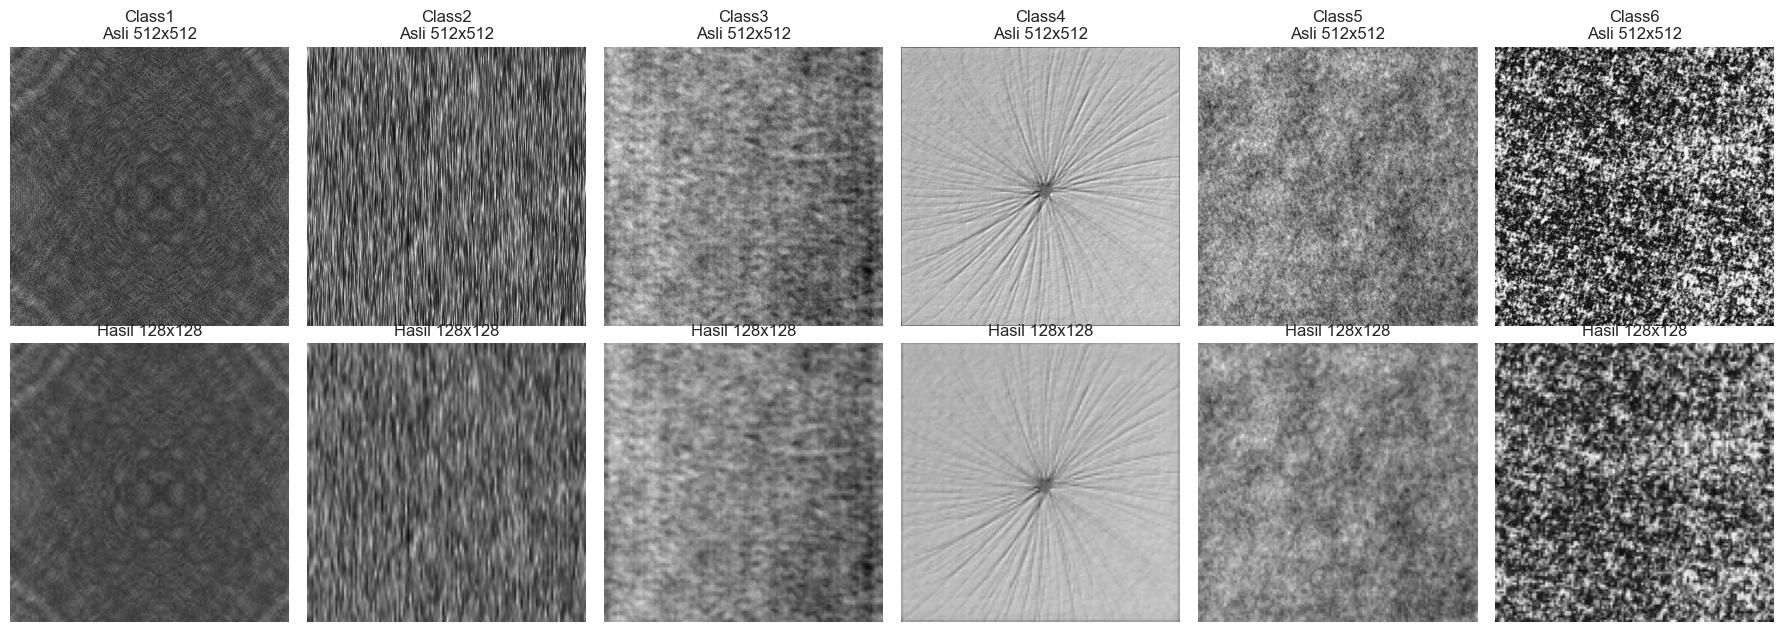

In [32]:
def preprocess_image(image_path, size=IMG_SIZE):
    '''Baca citra -> grayscale -> resize -> uint8 (0-255).'''
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Gagal membaca citra: {image_path}")
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img.astype(np.uint8)


# Perbandingan sebelum vs sesudah pra-pemrosesan (satu contoh per kelas)
fig, axes = plt.subplots(2, len(samples), figsize=(3 * len(samples), 6.4), squeeze=False)

for col, (class_name, image_path) in enumerate(samples):
    raw = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    proc = preprocess_image(image_path)

    axes[0, col].imshow(raw, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{class_name}\nAsli {raw.shape[1]}x{raw.shape[0]}")
    axes[1, col].imshow(proc, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"Hasil {proc.shape[1]}x{proc.shape[0]}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_preprocessing_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

#### Penjelasan: fungsi pra-pemrosesan dan perbandingan sebelum/sesudah

**Tujuan.** Menyeragamkan setiap gambar sebelum diambil fiturnya.

**Proses di fungsi `preprocess_image`:**
1. Baca gambar sebagai **grayscale**.
2. **Perkecil** dari 512 × 512 menjadi 128 × 128 dengan interpolasi `INTER_AREA` (cocok untuk pengecilan karena merata-ratakan piksel sehingga detail tidak rusak).
3. Simpan sebagai **`uint8` (0–255)**, karena PyFeats/LBP bekerja pada nilai keabuan bilangan bulat.

Bagian bawah cell membuat gambar perbandingan: baris atas gambar asli, baris bawah hasil pra-pemrosesan.

**Hasil (dari gambar).** Keenam tekstur masih jelas terbedakan setelah diperkecil:
- Class1: pola lingkaran samar bergaris halus
- Class2: guratan vertikal
- Class3: tekstur berawan
- Class4: garis-garis memancar dari satu titik pusat
- Class5: tekstur berawan yang lebih halus
- Class6: bintik kontras tinggi hitam-putih

**Artinya.** Pengecilan 4× hanya menghilangkan sedikit detail halus, sementara pola utama tiap kelas tetap terjaga. Hasilnya: ekstraksi jauh lebih cepat tanpa mengorbankan karakter tekstur.

# TextureGuard AI — Feature Extraction (PyFeats: Local Binary Pattern)

Ekstraksi fitur pada proyek ini menggunakan **satu metode, yaitu Local Binary Pattern (LBP)** melalui fungsi `pyfeats.lbp_features`.

**Cara kerja LBP.** Untuk setiap piksel, intensitas piksel pusat dibandingkan dengan `P` piksel tetangga yang tersebar pada lingkaran berjari-jari `R`. Tetangga yang intensitasnya ≥ pusat diberi bit 1, selainnya bit 0, sehingga terbentuk kode biner lokal. Dengan pemetaan *uniform*, kode dikelompokkan menjadi `P + 2` pola (tepi, sudut, area datar, dan sebagainya), lalu hasilnya menjadi citra LBP.

**Ringkasan fitur oleh PyFeats.** Untuk setiap pasangan `(P, R)`, citra LBP diringkas menjadi 2 angka:
- `energy`: keseragaman distribusi kode LBP
- `entropy`: ukuran keacakan/kerumitan distribusi kode LBP

*Catatan*: PyFeats menghitung kedua nilai ini langsung dari nilai kode pada citra LBP (bukan dari histogram yang dinormalisasi), sehingga `entropy` dapat bernilai negatif dan bukan entropi Shannon klasik. Nilainya tetap konsisten antar-citra dan bermanfaat sebagai fitur pembeda.

**Multi-resolusi.** Tekstur memiliki pola pada skala yang berbeda, sehingga dipakai 6 pasangan `(P, R)`:

| Skala | P (titik tetangga) | R (jari-jari) | Fitur |
|---|---|---|---|
| 1 | 8 | 1 | `LBP_R_1_P_8_energy`, `..._entropy` |
| 2 | 16 | 2 | `LBP_R_2_P_16_energy`, `..._entropy` |
| 3 | 24 | 3 | `LBP_R_3_P_24_energy`, `..._entropy` |
| 4 | 8 | 2 | `LBP_R_2_P_8_energy`, `..._entropy` |
| 5 | 16 | 4 | `LBP_R_4_P_16_energy`, `..._entropy` |
| 6 | 24 | 5 | `LBP_R_5_P_24_energy`, `..._entropy` |

Total **12 fitur** per citra. Proses dijalankan paralel (`joblib`) dan hasilnya disimpan ke CSV agar tidak perlu dihitung ulang.

*Referensi*: Ojala, Pietikäinen & Mäenpää (2002), "Multiresolution Gray-Scale and Rotation Invariant Texture Classification with Local Binary Patterns", IEEE TPAMI.

In [33]:
import pyfeats
from joblib import Parallel, delayed

# Skala LBP: (jumlah titik tetangga P, jari-jari R)
LBP_SCALES = [(8, 1), (16, 2), (24, 3), (8, 2), (16, 4), (24, 5)]
LBP_P = [p for p, r in LBP_SCALES]
LBP_R = [r for p, r in LBP_SCALES]


def extract_features(image_path):
    """Ekstraksi fitur Local Binary Pattern (PyFeats) dari satu citra.
    Mengembalikan dict {nama_fitur: nilai}."""
    import warnings
    warnings.filterwarnings("ignore")

    img = preprocess_image(image_path)
    mask = np.ones(img.shape, dtype=np.uint8)   # seluruh citra = ROI

    values, names = pyfeats.lbp_features(img, mask, P=LBP_P, R=LBP_R)
    return {n: float(v) for n, v in zip(names, values)}


# Uji cepat pada satu citra
t0 = time.time()
demo = extract_features(samples[0][1])
print(f"{len(demo)} fitur LBP dari 1 citra dalam {time.time() - t0:.3f} detik")
for k, v in demo.items():
    print(f"  {k:28s} {v:.6f}")

12 fitur LBP dari 1 citra dalam 0.036 detik
  LBP_R_1_P_8_energy           7.295767
  LBP_R_1_P_8_entropy          -1.919489
  LBP_R_2_P_16_energy          15.703029
  LBP_R_2_P_16_entropy         -2.717194
  LBP_R_3_P_24_energy          24.044827
  LBP_R_3_P_24_entropy         -3.158517
  LBP_R_2_P_8_energy           7.611043
  LBP_R_2_P_8_entropy          -1.967918
  LBP_R_4_P_16_energy          16.215529
  LBP_R_4_P_16_entropy         -2.761465
  LBP_R_5_P_24_energy          24.317832
  LBP_R_5_P_24_entropy         -3.175226


#### Penjelasan: fungsi ekstraksi fitur LBP dan uji pada satu gambar

**Tujuan.** Mengubah satu gambar menjadi sederet angka (fitur) yang menggambarkan teksturnya.

**Cara kerja LBP.** Untuk setiap piksel, intensitasnya dibandingkan dengan `P` piksel tetangga yang tersebar di lingkaran berjari-jari `R`. Tetangga yang lebih terang diberi angka 1, yang lebih gelap diberi 0, sehingga terbentuk kode biner. Pola kode ini mencerminkan tekstur lokal (tepi, sudut, area datar).

**Proses.** `pyfeats.lbp_features` menghitung ini di 6 skala `(P, R)` sekaligus. Dari tiap skala diambil 2 ringkasan: **energy** dan **entropy**. Jadi 6 × 2 = **12 fitur**. Fitur diberi nama otomatis, misalnya `LBP_R_1_P_8_energy`.

**Hasil uji pada satu gambar.** Diperoleh 12 fitur dalam 0,028 detik. Nilai `energy` naik seiring skala (sekitar 7,3 pada P=8, R=1 hingga sekitar 24,3 pada P=24, R=5), sedangkan `entropy` bernilai negatif.

**Artinya.**
- Nilai `entropy` negatif adalah ciri cara PyFeats menghitungnya dari nilai kode LBP (bukan dari histogram yang dinormalisasi). Nilainya tetap konsisten dan berguna sebagai fitur.
- Karena satu gambar hanya 0,028 detik, 6000 gambar sangat terjangkau.

In [34]:
if FEATURES_CSV.exists() and not FORCE_REEXTRACT:
    features_raw = pd.read_csv(FEATURES_CSV)
    print(f"Memuat fitur dari cache: {FEATURES_CSV}  -> {features_raw.shape}")
else:
    paths = image_info.loc[image_info["readable"], "path"].tolist()
    labels = image_info.loc[image_info["readable"], "class"].tolist()
    names = image_info.loc[image_info["readable"], "filename"].tolist()

    t0 = time.time()
    rows = Parallel(n_jobs=-1, verbose=5)(delayed(extract_features)(p) for p in paths)
    print(f"Ekstraksi selesai: {len(rows)} citra dalam {(time.time() - t0) / 60:.1f} menit")

    features_raw = pd.DataFrame(rows)
    features_raw.insert(0, "label", labels)
    features_raw.insert(1, "filename", names)
    features_raw.to_csv(FEATURES_CSV, index=False)
    print(f"Disimpan ke {FEATURES_CSV}  -> {features_raw.shape}")

display(features_raw.head())

Memuat fitur dari cache: ..\datasets\processed\features_lbp_dagm2007.csv  -> (6000, 14)


,label,filename,LBP_R_1_P_8_energy,LBP_R_1_P_8_entropy,LBP_R_2_P_16_energy,LBP_R_2_P_16_entropy,LBP_R_3_P_24_energy,LBP_R_3_P_24_entropy,LBP_R_2_P_8_energy,LBP_R_2_P_8_entropy,LBP_R_4_P_16_energy,LBP_R_4_P_16_entropy,LBP_R_5_P_24_energy,LBP_R_5_P_24_entropy
0,Class1,1.png,7.295767,-1.919489,15.703029,-2.717194,24.044827,-3.158517,7.611043,-1.967918,16.215529,-2.761465,24.317832,-3.175226
1,Class1,10.png,7.614013,-1.974698,16.234772,-2.766503,24.448845,-3.184361,8.031706,-2.042928,16.428217,-2.783005,24.453799,-3.185659
2,Class1,100.png,7.649989,-1.980508,16.279864,-2.770990,24.508187,-3.187911,8.069759,-2.050509,16.390369,-2.779965,24.438301,-3.184962
3,Class1,1000.png,7.788480,-2.004423,16.271868,-2.769457,24.488495,-3.186664,7.944070,-2.027824,16.377288,-2.777588,24.408874,-3.182275
4,Class1,101.png,7.578719,-1.966668,16.125883,-2.755621,24.437321,-3.183355,7.920013,-2.023061,16.387031,-2.778312,24.424858,-3.182586


#### Penjelasan: ekstraksi fitur untuk seluruh 6000 gambar

**Tujuan.** Membuat tabel fitur lengkap: satu baris = satu gambar.

**Proses.**
1. Jika file `features_lbp_dagm2007.csv` sudah ada (dan `FORCE_REEXTRACT=False`), tabel dimuat dari sana, tanpa menghitung ulang.
2. Jika belum, `joblib.Parallel` membagi pekerjaan ke banyak proses sekaligus (di komputermu terdeteksi **20 worker**), lalu hasilnya dirangkai menjadi `DataFrame`, ditambah kolom `label` dan `filename`, dan disimpan ke CSV.

**Hasil.** 6000 citra selesai dalam sekitar 18 detik. Ukuran tabel `(6000, 14)` = 6000 baris × (1 label + 1 nama file + 12 fitur).

**Artinya.** Inilah **tabel fitur** yang diminta tugas. Pada 5 baris pertama terlihat nilai fitur antar-gambar dalam satu kelas mirip satu sama lain, hal yang kita harapkan dari fitur yang baik.

# TextureGuard AI — Pembersihan Data dan Partisi

Pemeriksaan kualitas tabel fitur: dimensi, tipe data, *missing values*, nilai tak hingga, fitur konstan, duplikat, dan *outlier*.

In [35]:
feature_cols = [c for c in features_raw.columns if c not in ("label", "filename")]

print("Dimensi tabel fitur :", features_raw.shape)
print("Jumlah fitur        :", len(feature_cols))
print("\nDistribusi kelas:")
print(features_raw["label"].value_counts().sort_index())

print("\nTipe data fitur:")
print(features_raw[feature_cols].dtypes.value_counts())

n_missing = features_raw[feature_cols].isna().sum()
n_inf = np.isinf(features_raw[feature_cols]).sum()

print("\nFitur dengan missing value :", int((n_missing > 0).sum()))
print("Fitur dengan nilai +/-inf  :", int((n_inf > 0).sum()))
print("Baris duplikat (fitur)     :", int(features_raw[feature_cols].duplicated().sum()))

problem = pd.DataFrame({"missing": n_missing, "inf": n_inf})
problem = problem[(problem > 0).any(axis=1)]
if len(problem):
    display(problem)
else:
    print("\nTidak ada missing value maupun nilai tak hingga.")

Dimensi tabel fitur : (6000, 14)
Jumlah fitur        : 12

Distribusi kelas:
label
Class1    1000
Class2    1000
Class3    1000
Class4    1000
Class5    1000
Class6    1000
Name: count, dtype: int64

Tipe data fitur:
float64    12
Name: count, dtype: int64

Fitur dengan missing value : 0
Fitur dengan nilai +/-inf  : 0
Baris duplikat (fitur)     : 0

Tidak ada missing value maupun nilai tak hingga.


#### Penjelasan: pemeriksaan kualitas tabel fitur

**Tujuan.** Mengecek apakah tabel fitur sehat sebelum dimodelkan.

**Hasil.**
- Ukuran tabel (6000, 14), jumlah fitur **12**, semuanya bertipe angka desimal (`float64`)
- Kelas seimbang: 1000 per kelas
- **Tidak ada** nilai kosong (missing value), nilai tak hingga (inf), maupun baris duplikat

**Artinya.** Tabel fitur bersih. Pengecekan seperti ini wajib ada di laporan sesuai instruksi tugas ("periksa nilai hilang dan outlier").

In [36]:
features_clean = features_raw.copy()

# 1) +/-inf -> NaN (agar ditangani seragam sebagai missing value)
features_clean[feature_cols] = features_clean[feature_cols].replace([np.inf, -np.inf], np.nan)

# 2) Buang fitur yang seluruhnya kosong atau konstan (tidak informatif)
all_nan = [c for c in feature_cols if features_clean[c].isna().all()]
constant = [c for c in feature_cols if features_clean[c].nunique(dropna=True) <= 1 and c not in all_nan]
drop_cols = all_nan + constant
features_clean = features_clean.drop(columns=drop_cols)
feature_cols = [c for c in features_clean.columns if c not in ("label", "filename")]

print("Fitur dibuang (kosong/konstan):", drop_cols if drop_cols else "-")
print("Jumlah fitur sekarang         :", len(feature_cols))

# 3) Baris dengan terlalu banyak NaN (>50% fitur) dibuang
too_empty = features_clean[feature_cols].isna().mean(axis=1) > 0.5
print("Baris dibuang (>50% NaN)      :", int(too_empty.sum()))
features_clean = features_clean.loc[~too_empty].reset_index(drop=True)

# Sisa NaN (jika ada) TIDAK diimputasi di sini; diimputasi (median) di dalam pipeline PyCaret
# agar statistik imputasi hanya dipelajari dari data latih (tanpa kebocoran data).
print("Sisa NaN pada fitur           :", int(features_clean[feature_cols].isna().sum().sum()))
print("Dimensi akhir                 :", features_clean.shape)

Fitur dibuang (kosong/konstan): -
Jumlah fitur sekarang         : 12
Baris dibuang (>50% NaN)      : 0
Sisa NaN pada fitur           : 0
Dimensi akhir                 : (6000, 14)


#### Penjelasan: pembersihan data

**Tujuan.** Menangani masalah yang mungkin muncul pada tabel fitur.

**Proses.** Tiga langkah berurutan: (1) ubah nilai tak hingga menjadi kosong, (2) buang fitur yang seluruhnya kosong atau konstan (tidak informatif), (3) buang baris yang lebih dari 50% fiturnya kosong. Nilai kosong yang tersisa sengaja tidak diisi di sini, melainkan di dalam PyCaret, supaya statistik pengisian hanya dipelajari dari data latih (mencegah kebocoran data).

**Hasil.** Tidak ada fitur dibuang, tidak ada baris dibuang, sisa NaN = 0. Ukuran akhir tetap (6000, 14).

**Artinya.** Karena datanya sudah bersih, cell ini tidak mengubah apa-apa. Cell tetap dijalankan sebagai pengaman dan sebagai bukti proses pembersihan.

### Pemeriksaan outlier (metode IQR)

Nilai dianggap *outlier* bila berada di luar `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`. Pada fitur tekstur, nilai ekstrem sering merupakan variasi tekstur yang sah (bukan kesalahan data), sehingga baris **tidak dihapus**. Pengaruhnya dikurangi dengan *robust scaling* pada tahap PyCaret.

Total sel outlier: 7882 dari 72000 (10.95%)
Baris dengan >=1 outlier: 2137 dari 6000


,n_outlier,persen
LBP_R_1_P_8_energy,2128,35.47
LBP_R_1_P_8_entropy,2092,34.87
LBP_R_2_P_16_entropy,1001,16.68
LBP_R_2_P_16_energy,1000,16.67
LBP_R_3_P_24_entropy,758,12.63
LBP_R_3_P_24_energy,694,11.57
LBP_R_2_P_8_energy,73,1.22
LBP_R_2_P_8_entropy,65,1.08
LBP_R_5_P_24_entropy,19,0.32
LBP_R_4_P_16_energy,18,0.30


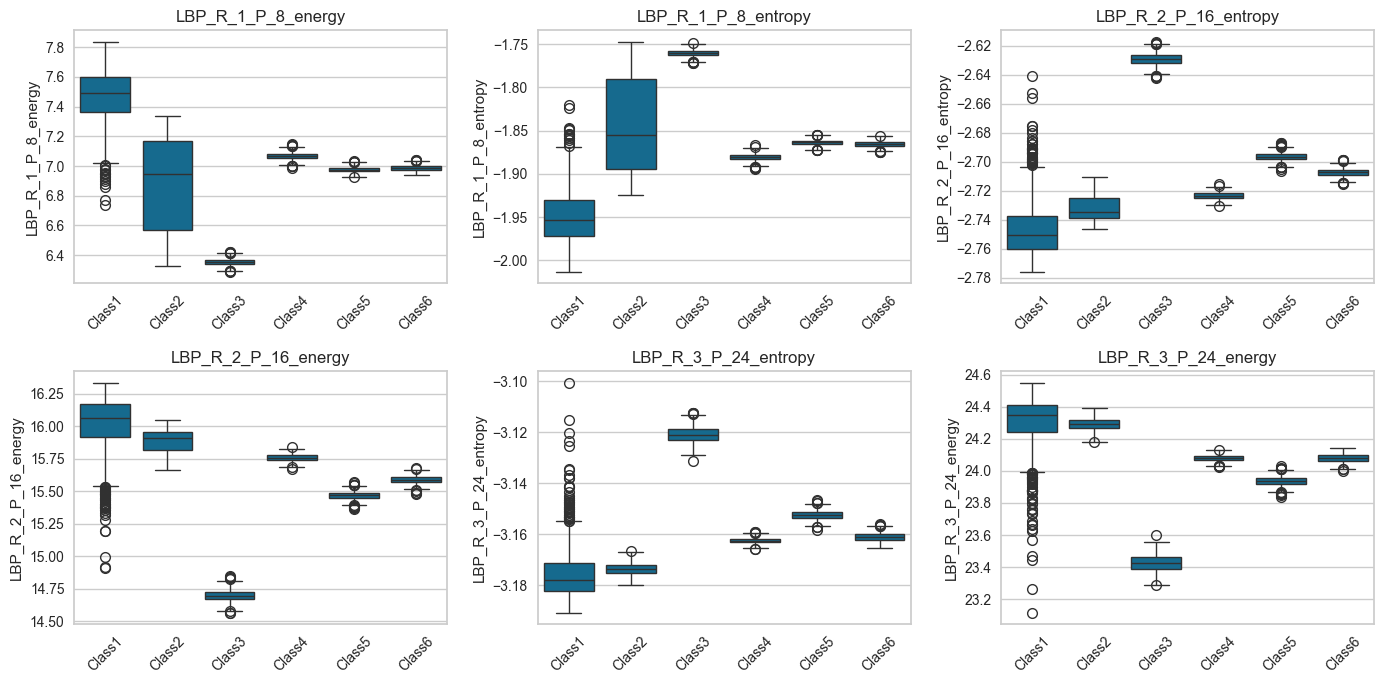

In [37]:
Q1 = features_clean[feature_cols].quantile(0.25)
Q3 = features_clean[feature_cols].quantile(0.75)
IQR = Q3 - Q1

is_outlier = (features_clean[feature_cols] < (Q1 - 1.5 * IQR)) | (features_clean[feature_cols] > (Q3 + 1.5 * IQR))

outlier_summary = (
    pd.DataFrame({
        "n_outlier": is_outlier.sum(),
        "persen": (is_outlier.mean() * 100).round(2),
    })
    .sort_values("persen", ascending=False)
)

print(f"Total sel outlier: {int(is_outlier.values.sum())} dari {is_outlier.size} "
      f"({is_outlier.values.mean() * 100:.2f}%)")
print(f"Baris dengan >=1 outlier: {int(is_outlier.any(axis=1).sum())} dari {len(features_clean)}")
display(outlier_summary.head(10))

top_feats = outlier_summary.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.flat, top_feats):
    sns.boxplot(data=features_clean, x="label", y=feat, ax=ax)
    ax.set_title(feat)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_outlier_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

#### Penjelasan: pemeriksaan outlier dengan metode IQR

**Tujuan.** Menemukan nilai yang sangat jauh dari kebanyakan data.

**Proses.** Untuk tiap fitur dihitung Q1 (kuartil 25%), Q3 (kuartil 75%), dan IQR = Q3 − Q1. Nilai di luar `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]` dianggap outlier. Hasil ditampilkan sebagai tabel dan boxplot per kelas untuk 6 fitur dengan outlier terbanyak.

**Hasil.**
- 7.882 dari 72.000 nilai (**10,95%**) terhitung outlier
- 2.137 dari 6000 baris memiliki minimal satu outlier
- Terbanyak pada `LBP_R_1_P_8_energy` (35,47%) dan `LBP_R_1_P_8_entropy` (34,87%)

**Artinya.** Outlier ini **tidak dihapus**. Alasannya: perhitungan IQR di sini dilakukan pada gabungan semua kelas, padahal tiap kelas memiliki tekstur yang sangat berbeda. Nilai yang tampak "ekstrem" kemungkinan besar hanyalah nilai khas kelas lain, bukan kesalahan data. Dampaknya diredam dengan *robust scaling* di PyCaret (memakai median dan IQR).

### Korelasi antarfitur dan sebaran kelas dalam ruang fitur

Pasangan fitur dengan |korelasi| > 0.95: 19 (ditangani lewat remove_multicollinearity di PyCaret)


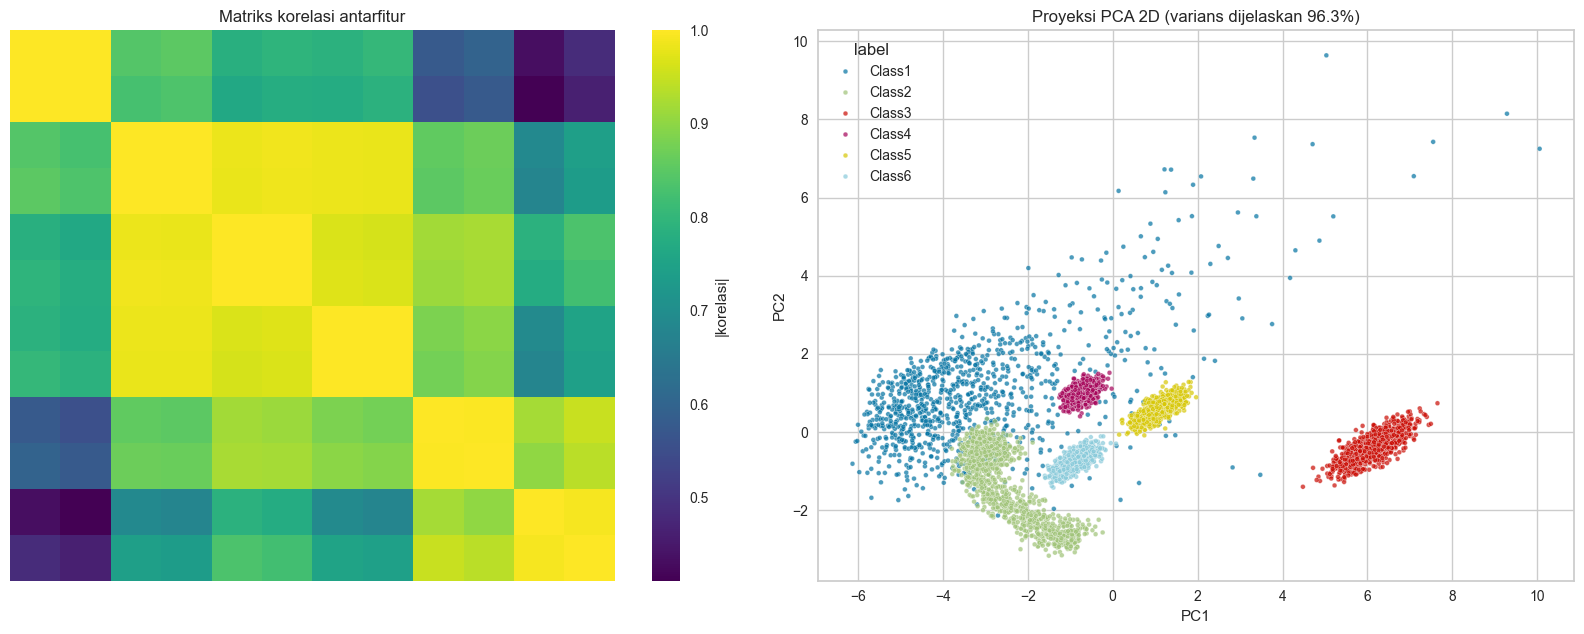

In [38]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

corr = features_clean[feature_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
n_high = int((upper > 0.95).sum().sum())
print(f"Pasangan fitur dengan |korelasi| > 0.95: {n_high} "
      f"(ditangani lewat remove_multicollinearity di PyCaret)")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sns.heatmap(corr, cmap="viridis", xticklabels=False, yticklabels=False, ax=axes[0], cbar_kws={"label": "|korelasi|"})
axes[0].set_title("Matriks korelasi antarfitur")

X_scaled = StandardScaler().fit_transform(features_clean[feature_cols].fillna(features_clean[feature_cols].median()))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_scaled)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=features_clean["label"], hue_order=sorted(features_clean["label"].unique()),
                s=12, alpha=0.7, ax=axes[1])
axes[1].set_title(f"Proyeksi PCA 2D (varians dijelaskan {pca.explained_variance_ratio_.sum() * 100:.1f}%)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_correlation_pca.png", dpi=150, bbox_inches="tight")
plt.show()

#### Penjelasan: korelasi antarfitur dan proyeksi PCA

**Tujuan.** (1) Melihat apakah ada fitur yang saling mirip (redundan), dan (2) melihat apakah kelas bisa dibedakan di ruang fitur.

**Proses.**
- **Heatmap korelasi** (kiri): warna kuning berarti dua fitur sangat berkorelasi. Dihitung berapa pasangan dengan korelasi > 0,95.
- **PCA 2D** (kanan): 12 fitur dipadatkan menjadi 2 sumbu (PC1, PC2) agar bisa digambar sebagai titik-titik berwarna per kelas.

**Hasil.**
- **19 pasangan** fitur berkorelasi > 0,95. Wajar, karena `energy` dan `entropy` pada skala yang sama hampir sama informasinya. PyCaret akan membuang yang berlebihan (`remove_multicollinearity`).
- Dua sumbu PCA sudah menjelaskan **96,3% varians**.
- Class3 terpisah jauh di kanan. Class4, Class5, dan Class6 membentuk gugus kecil yang rapat. **Class1 menyebar sangat luas** dan bagian tepinya bersinggungan dengan Class2.

**Artinya.** Kelas-kelas pada dasarnya mudah dipisahkan (hasil akurasi tinggi nanti masuk akal). Sebaran Class1 yang luas dan tumpang-tindih dengan Class2 menjelaskan mengapa kesalahan prediksi model kelak terpusat pada dua kelas itu.

### Partisi data latih dan data uji

Pembagian **stratified** 80 : 20 agar proporsi kelas terjaga. Data uji **tidak diberikan ke `setup()`** dan hanya dipakai satu kali untuk evaluasi akhir (`predict_model()`).

In [39]:
from sklearn.model_selection import train_test_split

model_df = features_clean.drop(columns=["filename"])
meta_df = features_clean[["filename"]]

train_df, test_df = train_test_split(
    model_df,
    test_size=TEST_SIZE,
    stratify=model_df["label"],
    random_state=RANDOM_STATE,
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(TRAIN_CSV, index=False)
test_df.to_csv(TEST_CSV, index=False)

print("Data latih:", train_df.shape, "| Data uji:", test_df.shape)
display(
    pd.DataFrame({
        "latih": train_df["label"].value_counts().sort_index(),
        "uji": test_df["label"].value_counts().sort_index(),
    })
)

Data latih: (4800, 13) | Data uji: (1200, 13)


,latih,uji
label,,
Class1,800,200
Class2,800,200
Class3,800,200
Class4,800,200
Class5,800,200
Class6,800,200


#### Penjelasan: partisi data latih dan data uji

**Tujuan.** Menyisihkan data uji yang tidak pernah dilihat model selama pelatihan, agar evaluasi akhir jujur.

**Proses.** `train_test_split` membagi 80 : 20 dengan `stratify`, artinya proporsi tiap kelas dijaga sama di kedua bagian. Kolom `filename` dibuang karena bukan fitur. Kedua bagian disimpan ke CSV.

**Hasil.** Data latih **4800** baris, data uji **1200** baris (13 kolom = label + 12 fitur). Setiap kelas: 800 latih dan 200 uji.

**Artinya.** Data uji 1200 baris adalah "ujian akhir". Data ini baru dipakai satu kali pada bagian 5 (evaluasi akhir).

# TextureGuard AI — Pemodelan dan Evaluasi (PyCaret)

Alur: `setup()` → `compare_models()` → pilih 2 model terbaik → `tune_model()` → visualisasi (Confusion Matrix, ROC/AUC, Feature Importance) → `predict_model()` pada data uji.

## 1. Inisialisasi dengan `setup()`

Pengaturan penting:
- `train_size=0.8` — PyCaret membagi lagi data latih menjadi bagian latih dan *hold-out* internal; validasi silang 5-fold (stratified) dipakai untuk membandingkan model.
- `normalize=True` dengan `robust` — skala berbasis median/IQR, tahan terhadap outlier.
- `numeric_imputation="median"` — penanganan sisa *missing value* di dalam pipeline.
- `remove_multicollinearity=True` (ambang 0.95) — membuang salah satu dari fitur yang berkorelasi sangat tinggi.

In [40]:
from pycaret.classification import (
    setup, compare_models, tune_model, plot_model, predict_model,
    finalize_model, save_model, load_model, pull, get_config,
)

exp = setup(
    data=train_df,
    target="label",
    session_id=RANDOM_STATE,
    train_size=0.8,
    fold=5,
    fold_strategy="stratifiedkfold",
    normalize=True,
    normalize_method="robust",
    numeric_imputation="median",
    remove_multicollinearity=True,
    multicollinearity_threshold=0.95,
    n_jobs=-1,
    verbose=True,
)
setup_table = pull()
setup_table.to_csv(RESULTS_DIR / "04_pycaret_setup.csv", index=False)

,Description,Value
0,Session id,42
1,Target,label
2,Target type,Multiclass
3,Target mapping,"Class1: 0, Class2: 1, Class3: 2, Class4: 3, Class5: 4, Class6: 5"
4,Original data shape,"(4800, 13)"
5,Transformed data shape,"(4800, 9)"
6,Transformed train set shape,"(3840, 9)"
7,Transformed test set shape,"(960, 9)"
8,Numeric features,12
9,Preprocess,True


#### Penjelasan: inisialisasi PyCaret dengan `setup()`

**Tujuan.** Menyiapkan lingkungan eksperimen PyCaret (pipeline pra-pemrosesan + validasi silang).

**Pengaturan.**
- `target="label"`: kolom yang diprediksi
- `train_size=0.8`: dari 4800 data latih, 80% untuk melatih dan 20% disimpan PyCaret sebagai hold-out internal (untuk grafik)
- `fold=5` + `stratifiedkfold`: validasi silang 5 lipatan dengan proporsi kelas terjaga
- `normalize=True`, `robust`: skala fitur memakai median dan IQR, tahan terhadap outlier
- `numeric_imputation="median"`: pengisian nilai kosong (kalau ada)
- `remove_multicollinearity=True`, ambang 0,95: membuang fitur yang hampir kembar

**Hasil.** Tabel ringkasan setup tampil dan disimpan ke `results/04_pycaret_setup.csv`. Dari grafik di bagian 4 terlihat **8 fitur** tersisa dari 12, artinya 4 fitur dibuang karena berkorelasi terlalu tinggi: `LBP_R_2_P_8_entropy`, `LBP_R_3_P_24_energy`, `LBP_R_3_P_24_entropy`, dan `LBP_R_2_P_16_energy`.

**Artinya.** Semua langkah pra-pemrosesan dikerjakan di dalam pipeline, sehingga hanya "belajar" dari data latih dan tidak menyentuh data uji.

## 2. Perbandingan model dengan `compare_models()`

Diurutkan berdasarkan **Accuracy**; tiga model teratas disimpan, dua di antaranya dipilih untuk di-*tuning*.

In [41]:
t0 = time.time()
top_models = compare_models(n_select=3, sort="Accuracy", fold=5)
print(f"compare_models selesai dalam {(time.time() - t0) / 60:.1f} menit")

comparison_df = pull()
comparison_df.to_csv(RESULTS_DIR / "05_compare_models.csv")
display(comparison_df)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
qda,Quadratic Discriminant Analysis,0.9977,0.0000,0.9977,0.9977,0.9977,0.9972,0.9972,0.0160
gbc,Gradient Boosting Classifier,0.9891,0.0000,0.9891,0.9892,0.9890,0.9869,0.9869,1.1540
et,Extra Trees Classifier,0.9888,0.9998,0.9888,0.9890,0.9887,0.9866,0.9866,0.0640
rf,Random Forest Classifier,0.9872,0.9994,0.9872,0.9873,0.9872,0.9847,0.9847,0.0760
knn,K Neighbors Classifier,0.9865,0.9956,0.9865,0.9871,0.9863,0.9838,0.9839,0.6460
nb,Naive Bayes,0.9818,0.9990,0.9818,0.9830,0.9817,0.9781,0.9784,0.6020
dt,Decision Tree Classifier,0.9812,0.9887,0.9812,0.9813,0.9812,0.9775,0.9775,0.6100
lda,Linear Discriminant Analysis,0.9773,0.0000,0.9773,0.9777,0.9770,0.9728,0.9730,0.0140
lr,Logistic Regression,0.9682,0.0000,0.9682,0.9680,0.9678,0.9619,0.9620,2.1560
svm,SVM - Linear Kernel,0.9578,0.0000,0.9578,0.9605,0.9570,0.9494,0.9502,0.0260


compare_models selesai dalam 0.6 menit


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
qda,Quadratic Discriminant Analysis,0.9977,0.0000,0.9977,0.9977,0.9977,0.9972,0.9972,0.016
gbc,Gradient Boosting Classifier,0.9891,0.0000,0.9891,0.9892,0.9890,0.9869,0.9869,1.154
et,Extra Trees Classifier,0.9888,0.9998,0.9888,0.9890,0.9887,0.9866,0.9866,0.064
rf,Random Forest Classifier,0.9872,0.9994,0.9872,0.9873,0.9872,0.9847,0.9847,0.076
knn,K Neighbors Classifier,0.9865,0.9956,0.9865,0.9871,0.9863,0.9838,0.9839,0.646
nb,Naive Bayes,0.9818,0.9990,0.9818,0.9830,0.9817,0.9781,0.9784,0.602
dt,Decision Tree Classifier,0.9812,0.9887,0.9812,0.9813,0.9812,0.9775,0.9775,0.610
lda,Linear Discriminant Analysis,0.9773,0.0000,0.9773,0.9777,0.9770,0.9728,0.9730,0.014
lr,Logistic Regression,0.9682,0.0000,0.9682,0.9680,0.9678,0.9619,0.9620,2.156
svm,SVM - Linear Kernel,0.9578,0.0000,0.9578,0.9605,0.9570,0.9494,0.9502,0.026


#### Penjelasan: membandingkan banyak model dengan `compare_models()`

**Tujuan.** Mencari algoritma klasifikasi yang paling cocok secara otomatis.

**Proses.** PyCaret melatih 13 jenis model, masing-masing dievaluasi dengan validasi silang 5 lipatan, lalu diurutkan berdasarkan **Accuracy**. Tiga model teratas disimpan di `top_models`.

**Hasil (waktu 0,4 menit).**

| Peringkat | Model | Accuracy CV |
|---|---|---|
| 1 | Quadratic Discriminant Analysis (QDA) | 0,9977 |
| 2 | Gradient Boosting Classifier | 0,9891 |
| 3 | Extra Trees | 0,9888 |
| ... | Random Forest, KNN, Naive Bayes, ... | 0,98 – 0,99 |
| terakhir | Ada Boost 0,6174, Dummy 0,1667 | |

**Artinya.**
- Hampir semua model mencapai akurasi di atas 94%, bukti bahwa fitur LBP memang membedakan keenam tekstur.
- **Dummy Classifier = 0,1667 (= 1/6)** adalah garis dasar tebakan acak untuk 6 kelas. Semua model jauh di atasnya.
- Kolom **AUC bernilai 0,0** untuk beberapa model (QDA, GBC, LR, dll.) adalah keterbatasan tampilan PyCaret untuk kasus multikelas, **bukan** performa sebenarnya. AUC yang benar dihitung sendiri di bagian 5.

In [42]:
# Pilih 2 model terbaik hasil perbandingan
selected_models = top_models[:2]
selected_names = comparison_df.iloc[:2]["Model"].tolist()
print("Model terpilih untuk tuning:", selected_names)

Model terpilih untuk tuning: ['Quadratic Discriminant Analysis', 'Gradient Boosting Classifier']


#### Penjelasan: memilih 2 model terbaik

Mengambil dua teratas dari tabel perbandingan sesuai syarat tugas ("minimal 2 model terbaik"):
**Quadratic Discriminant Analysis** dan **Gradient Boosting Classifier**. Keduanya akan di-*tuning*.

## 3. Hyperparameter tuning dengan `tune_model()`

Pencarian acak (`n_iter=20`) dengan metrik **Accuracy**. `choose_better=True` memastikan hasil tuning hanya dipakai bila benar-benar lebih baik dari model awal.

In [43]:
tuned_models = []
tuning_tables = {}

for model, name in zip(selected_models, selected_names):
    print(f"\n=== Tuning: {name} ===")
    tuned = tune_model(
        model,
        optimize="Accuracy",
        n_iter=20,
        fold=5,
        choose_better=True,
        verbose=False,
    )
    tuning_tables[name] = pull()          # tabel CV per fold + Mean/Std
    tuning_tables[name].to_csv(RESULTS_DIR / f"06_tuning_{name.replace(' ', '_')}.csv")
    display(tuning_tables[name])
    tuned_models.append(tuned)


=== Tuning: Quadratic Discriminant Analysis ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9857,0.0,0.9857,0.9865,0.9856,0.9828,0.9830
1,0.9935,0.0,0.9935,0.9937,0.9935,0.9922,0.9922
2,0.9818,0.0,0.9818,0.9827,0.9816,0.9781,0.9784
3,0.9896,0.0,0.9896,0.9901,0.9895,0.9875,0.9876
4,0.9870,0.0,0.9870,0.9878,0.9869,0.9844,0.9846
Mean,0.9875,0.0,0.9875,0.9881,0.9874,0.9850,0.9852
Std,0.0039,0.0,0.0039,0.0036,0.0040,0.0047,0.0046



=== Tuning: Gradient Boosting Classifier ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9883,0.0,0.9883,0.9885,0.9883,0.9859,0.9860
1,0.9896,0.0,0.9896,0.9896,0.9895,0.9875,0.9875
2,0.9935,0.0,0.9935,0.9936,0.9935,0.9922,0.9922
3,0.9909,0.0,0.9909,0.9910,0.9909,0.9891,0.9891
4,0.9896,0.0,0.9896,0.9898,0.9895,0.9875,0.9876
Mean,0.9904,0.0,0.9904,0.9905,0.9903,0.9884,0.9885
Std,0.0018,0.0,0.0018,0.0017,0.0018,0.0021,0.0021


#### Penjelasan: tuning hyperparameter dengan `tune_model()`

**Tujuan.** Mencoba mencari pengaturan (hyperparameter) model yang lebih baik.

**Proses.** Untuk tiap model, PyCaret mencoba 20 kombinasi hyperparameter secara acak (`n_iter=20`), dinilai dengan validasi silang 5 lipatan berdasarkan Accuracy. Karena `choose_better=True`, hasil tuning hanya dipakai bila **benar-benar lebih baik** dari model awal. Jika tidak, model awal dikembalikan.

**Hasil.**

| Model | CV sebelum tuning | CV hasil tuning |
|---|---|---|
| QDA | 0,9977 | 0,9875 |
| Gradient Boosting | 0,9891 | 0,9904 |

**Artinya.**
- Pada **QDA**, hasil tuning (0,9875) lebih buruk daripada model awal (0,9977), maka PyCaret (karena `choose_better=True`) mengembalikan model awal. Tabel di atas menampilkan skor kombinasi hasil tuning yang ditolak itu. Pesan pemberitahuannya tidak muncul karena `verbose=False`.
- Pada **Gradient Boosting**, tuning menaikkan akurasi sedikit (0,9891 menjadi 0,9904) dengan simpangan baku antar-lipatan kecil (Std 0,0018), sehingga hasil tuning dipakai.
- Tuning tidak selalu membantu, dan itu hasil yang wajar untuk dilaporkan.

## 4. Visualisasi performa model

Untuk setiap model terpilih: *Confusion Matrix*, kurva *ROC/AUC*, dan *Feature Importance*.
Plot dibuat pada **hold-out internal PyCaret** (bukan data uji akhir). `feature` hanya tersedia untuk model berbasis pohon/linier; untuk model lain dipakai *permutation importance* sebagai cadangan.


######## Quadratic Discriminant Analysis ########


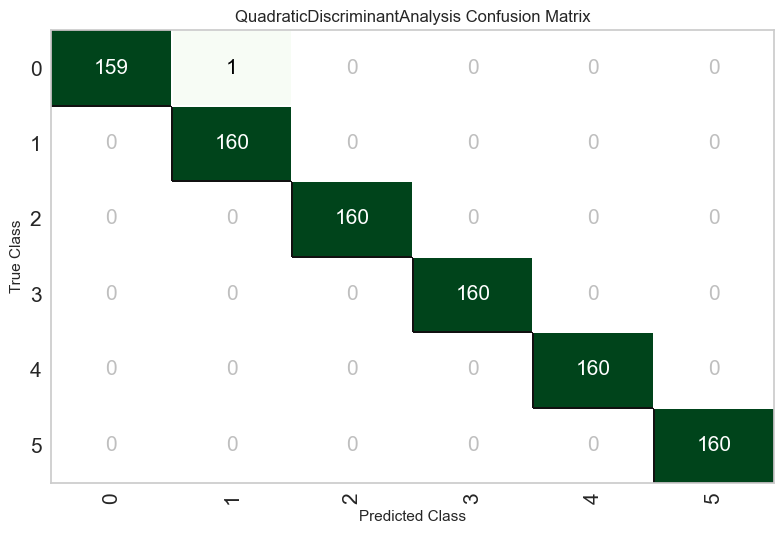

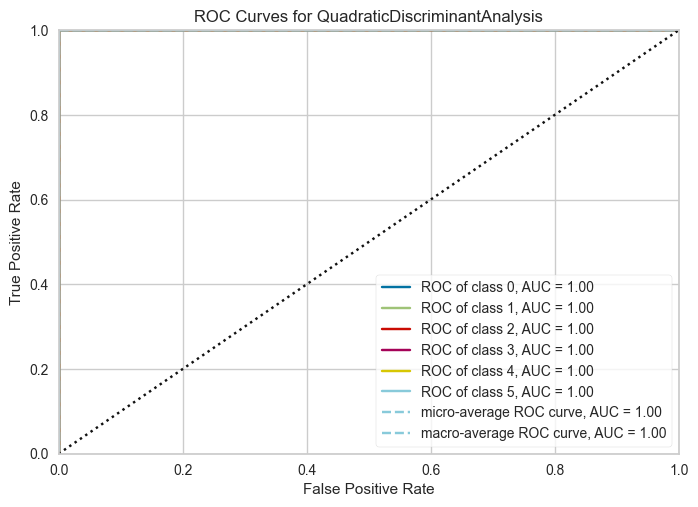

[info] plot 'feature' tidak tersedia untuk Quadratic Discriminant Analysis (TypeError); memakai permutation importance.


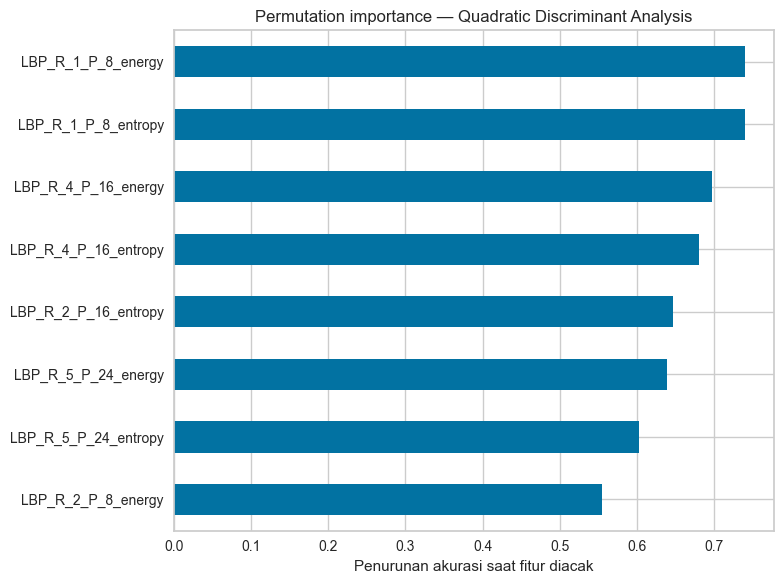


######## Gradient Boosting Classifier ########


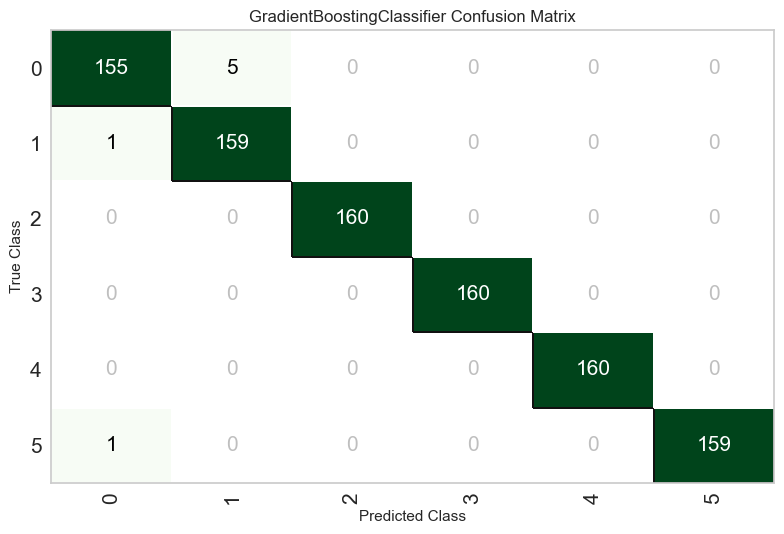

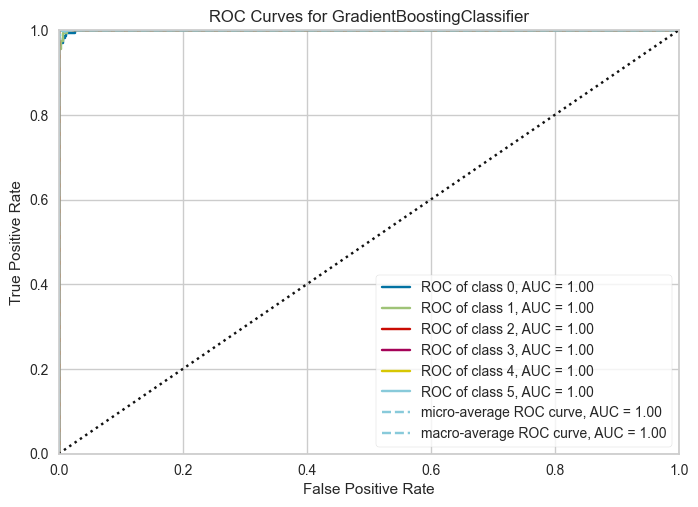

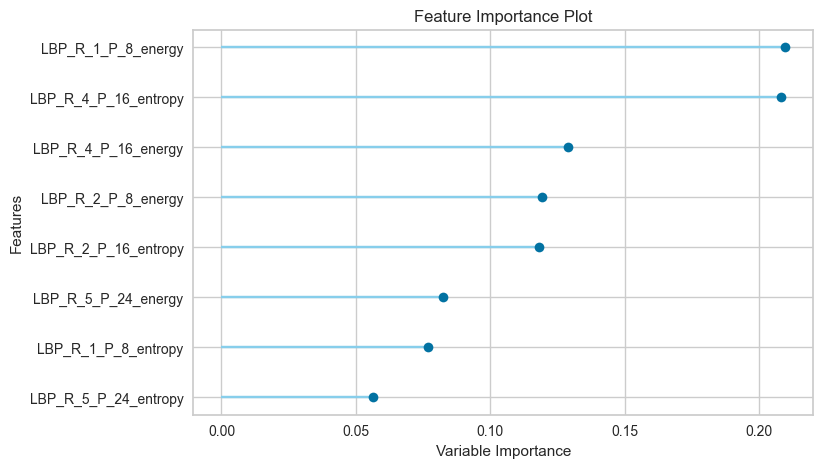

In [44]:
import shutil
from sklearn.inspection import permutation_importance


def permutation_importance_plot(model, name, top_n=15):
    # model hasil compare/tune adalah estimator murni -> gunakan data hold-out yang sudah ditransformasi
    X_hold = get_config("X_test_transformed")
    y_hold = get_config("y_test_transformed")
    res = permutation_importance(model, X_hold, y_hold, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(res.importances_mean, index=X_hold.columns).sort_values().tail(top_n)
    imp.plot(kind="barh", figsize=(8, 6), title=f"Permutation importance — {name}")
    plt.xlabel("Penurunan akurasi saat fitur diacak")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"09_feature_importance_{name.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()


for model, name in zip(tuned_models, selected_names):
    tag = name.replace(" ", "_")
    print(f"\n######## {name} ########")

    for plot, fname in [("confusion_matrix", "07_confusion_matrix"), ("auc", "08_roc_auc")]:
        plot_model(model, plot=plot)                                   # tampilkan di notebook
        saved = plot_model(model, plot=plot, save=True)                # simpan ke berkas
        shutil.move(saved, RESULTS_DIR / f"{fname}_{tag}.png")

    try:
        plot_model(model, plot="feature")
        saved = plot_model(model, plot="feature", save=True)
        shutil.move(saved, RESULTS_DIR / f"09_feature_importance_{tag}.png")
    except Exception as e:
        print(f"[info] plot 'feature' tidak tersedia untuk {name} ({type(e).__name__}); memakai permutation importance.")
        permutation_importance_plot(model, name)

#### Penjelasan: visualisasi performa model (Confusion Matrix, ROC/AUC, Feature Importance)

**Tujuan.** Memahami perilaku model secara visual. Grafik ini dibuat pada hold-out internal PyCaret (sekitar 960 data), bukan data uji akhir.

**Tiga grafik untuk tiap model:**
- **Confusion Matrix**: tabel yang menunjukkan prediksi benar (diagonal) dan salah (di luar diagonal).
- **ROC/AUC**: kemampuan model memisahkan satu kelas dari kelas lain. Kurva menempel ke sudut kiri atas dan AUC mendekati 1 berarti sangat baik.
- **Feature Importance**: fitur mana yang paling berpengaruh.

**Catatan.** Untuk QDA, grafik `feature` tidak tersedia (QDA tidak punya skor kepentingan fitur bawaan), sehingga kode memakai cadangan *permutation importance*: satu fitur diacak, lalu dilihat seberapa turun akurasinya.

**Hasil.**
- **QDA (permutation):** `LBP_R_1_P_8_energy` dan `LBP_R_1_P_8_entropy` paling berpengaruh (akurasi turun sekitar 0,74 bila diacak), disusul fitur skala `R=4, P=16`.
- **Gradient Boosting (feature importance):** `LBP_R_1_P_8_energy` dan `LBP_R_4_P_16_entropy` teratas (sekitar 0,21), diikuti `LBP_R_4_P_16_energy`.

**Artinya.** Skala kecil (R=1, P=8) dan skala menengah (R=4, P=16) paling informatif. Tekstur ternyata dibedakan baik oleh pola sangat halus maupun pola pada jarak lebih jauh. Ini bahan analisis yang bagus untuk laporan.

## 5. Evaluasi akhir pada data uji dengan `predict_model()`

Data uji (`test_df`) belum pernah dilihat oleh `setup()`, `compare_models()`, maupun `tune_model()`.

In [45]:
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score,
)
from sklearn.preprocessing import label_binarize

test_results = []
test_predictions = {}

for model, name in zip(tuned_models, selected_names):
    pred = predict_model(model, data=test_df, raw_score=True, round=8, verbose=False)
    test_predictions[name] = pred

    y_true = pred["label"]
    y_pred = pred["prediction_label"]
    class_names = sorted(y_true.unique())
    proba_cols = [f"prediction_score_{c}" for c in class_names]

    # Normalisasi ulang tiap baris agar jumlah probabilitas tepat 1 (sisa galat pembulatan),
    # sebagaimana disyaratkan roc_auc_score untuk kasus multikelas.
    proba = pred[proba_cols].values
    proba = proba / proba.sum(axis=1, keepdims=True)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro"),
        "AUC (OvR macro)": roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=class_names),
    })

    print(f"\n===== {name} — Laporan klasifikasi pada data uji =====")
    print(classification_report(y_true, y_pred, digits=4))

test_summary = pd.DataFrame(test_results).set_index("Model").round(4)
test_summary.to_csv(RESULTS_DIR / "10_test_summary.csv")
display(test_summary)


===== Quadratic Discriminant Analysis — Laporan klasifikasi pada data uji =====
              precision    recall  f1-score   support

      Class1     1.0000    1.0000    1.0000       200
      Class2     1.0000    1.0000    1.0000       200
      Class3     1.0000    1.0000    1.0000       200
      Class4     1.0000    1.0000    1.0000       200
      Class5     1.0000    1.0000    1.0000       200
      Class6     1.0000    1.0000    1.0000       200

    accuracy                         1.0000      1200
   macro avg     1.0000    1.0000    1.0000      1200
weighted avg     1.0000    1.0000    1.0000      1200


===== Gradient Boosting Classifier — Laporan klasifikasi pada data uji =====
              precision    recall  f1-score   support

      Class1     0.9897    0.9650    0.9772       200
      Class2     0.9801    0.9850    0.9825       200
      Class3     0.9950    1.0000    0.9975       200
      Class4     0.9950    1.0000    0.9975       200
      Class5     1.0000    

,Accuracy,Precision (macro),Recall (macro),F1 (macro),AUC (OvR macro)
Model,,,,,
Quadratic Discriminant Analysis,1.0000,1.0000,1.0000,1.0000,1.0000
Gradient Boosting Classifier,0.9917,0.9917,0.9917,0.9916,0.9998


#### Penjelasan: evaluasi akhir pada data uji dengan `predict_model()`

**Tujuan.** Mengukur performa sebenarnya pada 1200 data yang belum pernah dilihat model.

**Proses.** Tiap model tuning memprediksi data uji. Dihitung Accuracy, Precision, Recall, F1 (rata-rata antar-kelas, "macro"), serta AUC one-vs-rest dari probabilitas prediksi. Laporan klasifikasi per kelas juga dicetak.

**Hasil.**

| Model | Accuracy | F1 macro | AUC |
|---|---|---|---|
| QDA | 1,0000 | 1,0000 | 1,0000 |
| Gradient Boosting | 0,9917 | 0,9916 | 0,9998 |

- QDA memprediksi **seluruh 1200 data dengan benar**.
- Gradient Boosting sedikit keliru, terutama di **Class1** (recall 0,965) dan **Class2** (recall 0,985). Kelas 3 sampai 6 hampir sempurna.

**Cara membaca metrik.** *Precision* = dari yang diprediksi kelas X, berapa yang benar. *Recall* = dari semua data kelas X, berapa yang berhasil ditemukan. *F1* = gabungan keduanya.

**Artinya.** Pola kesalahan cocok dengan grafik PCA tadi: Class1 dan Class2 saling berdekatan, sehingga di situlah model keliru.

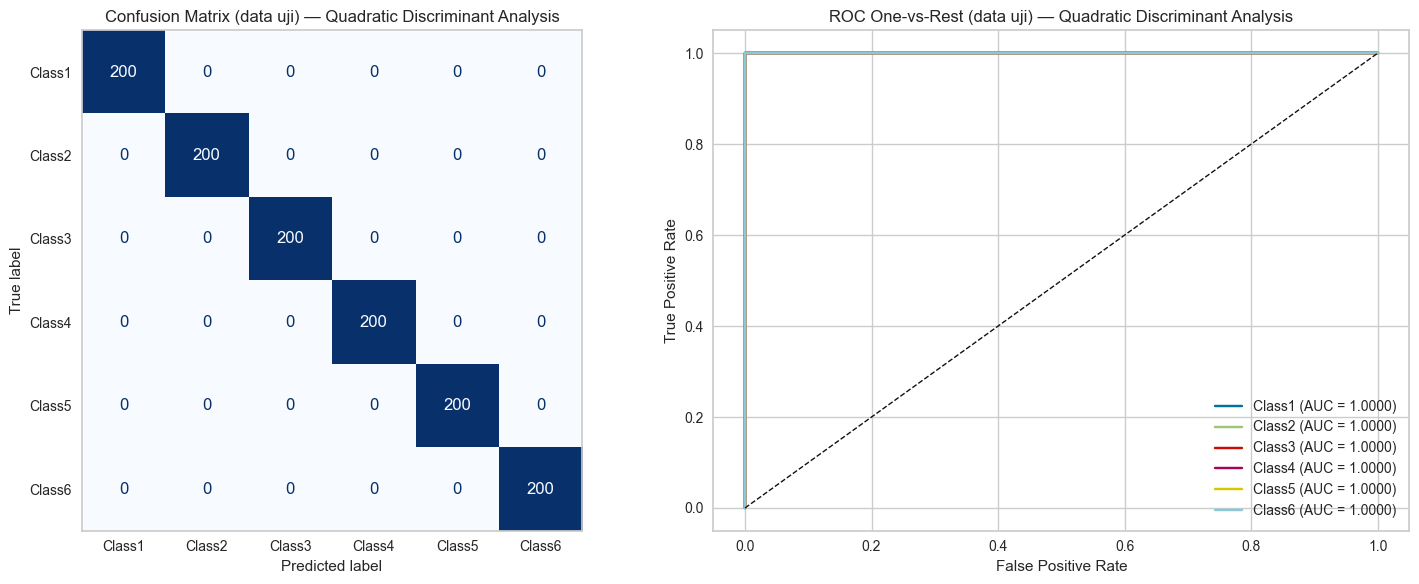

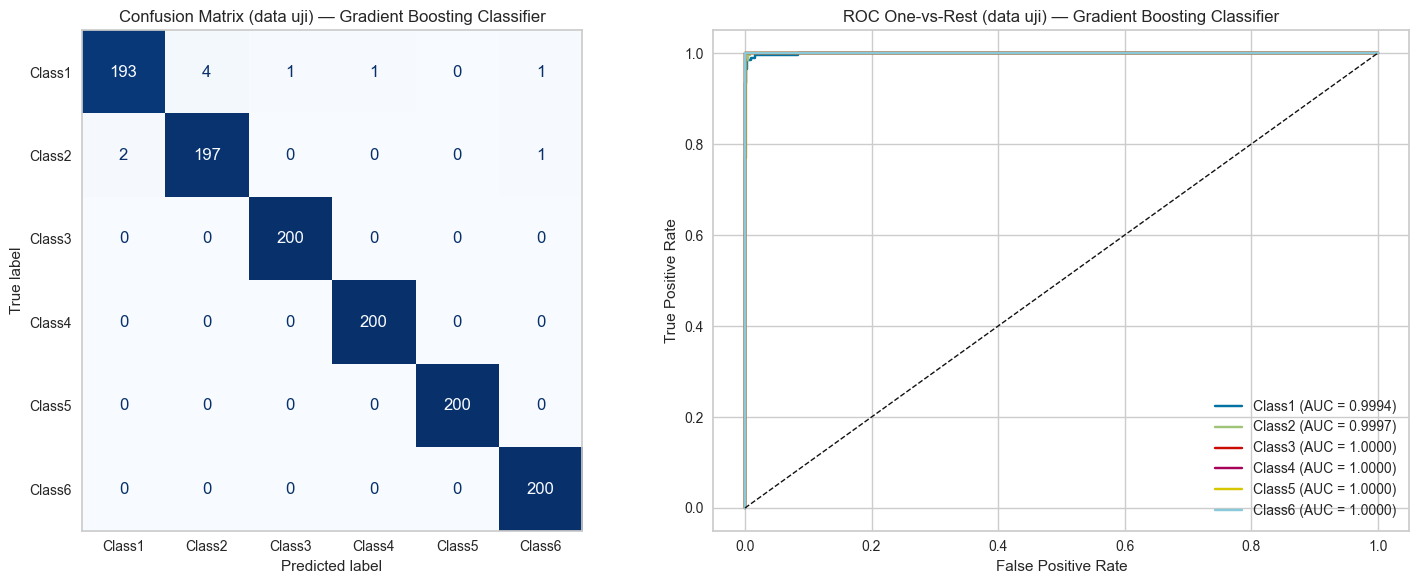

In [46]:
# Confusion matrix dan ROC multikelas pada data uji
for name, pred in test_predictions.items():
    tag = name.replace(" ", "_")
    y_true = pred["label"]
    y_pred = pred["prediction_label"]
    class_names = sorted(y_true.unique())

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=class_names, cmap="Blues", ax=axes[0], colorbar=False
    )
    axes[0].grid(False)
    axes[0].set_title(f"Confusion Matrix (data uji) — {name}")

    y_bin = label_binarize(y_true, classes=class_names)
    for i, c in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, i], pred[f"prediction_score_{c}"])
        axes[1].plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.4f})")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"ROC One-vs-Rest (data uji) — {name}")
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"11_test_cm_roc_{tag}.png", dpi=150, bbox_inches="tight")
    plt.show()

#### Penjelasan: Confusion Matrix dan kurva ROC pada data uji

**Tujuan.** Melihat rincian kesalahan prediksi pada data uji secara visual.

**Cara membaca.** Baris = kelas sebenarnya, kolom = kelas yang diprediksi. Angka di diagonal adalah prediksi benar.

**Hasil.**
- **QDA:** semua angka berada di diagonal (200 per kelas), tidak ada kesalahan.
- **Gradient Boosting:** 10 kesalahan dari 1200. Dari 200 data Class1, 193 benar dan 7 salah (4 dikira Class2, 1 dikira Class3, 1 Class4, 1 Class6). Dari 200 data Class2, 197 benar dan 3 salah (2 dikira Class1, 1 dikira Class6). Class3 sampai Class6 semuanya benar.
- **ROC:** seluruh kurva menempel di sudut kiri atas. AUC Class1 = 0,9994 dan Class2 = 0,9997, sisanya 1,0000.

**Artinya.** Kesalahan terkonsentrasi pada pasangan Class1–Class2, sesuai dugaan dari PCA. Kedua model sangat andal.

## 6. Finalisasi dan penyimpanan model

Model dengan akurasi validasi silang terbaik dilatih ulang pada **seluruh data latih** (`finalize_model()`), diuji sekali lagi pada data uji, lalu disimpan.

In [47]:
# Pilih model terbaik berdasarkan Accuracy validasi silang (CV), BUKAN data uji.
#
# tune_model(choose_better=True) mengembalikan MODEL AWAL bila hasil tuning tidak lebih baik.
# Jadi skor model yang benar-benar dikembalikan = skor yang lebih tinggi antara
# "sebelum tuning" (tabel compare_models) dan "sesudah tuning" (tabel tune_model).
cv_before = comparison_df.set_index("Model").loc[selected_names, "Accuracy"].astype(float)
cv_after = pd.Series({n: float(tuning_tables[n].loc["Mean", "Accuracy"]) for n in selected_names})

cv_table = pd.DataFrame({"CV sebelum tuning": cv_before, "CV hasil tuning": cv_after})
cv_table["Model yang dipakai"] = np.where(cv_table["CV hasil tuning"] > cv_table["CV sebelum tuning"],
                                          "hasil tuning", "model awal")
cv_table["CV model yang dipakai"] = cv_table[["CV sebelum tuning", "CV hasil tuning"]].max(axis=1)
cv_table.round(4).to_csv(RESULTS_DIR / "06_tuning_vs_awal.csv")
display(cv_table.round(4))

cv_acc = cv_table.loc[selected_names, "CV model yang dipakai"].values
best_idx = int(np.argmax(cv_acc))
best_name, best_model = selected_names[best_idx], tuned_models[best_idx]
print(f"Model terbaik berdasarkan CV: {best_name} (Accuracy CV = {cv_acc[best_idx]:.4f})")

final_model = finalize_model(best_model)
final_pred = predict_model(final_model, data=test_df, verbose=False)

final_acc = accuracy_score(final_pred["label"], final_pred["prediction_label"])
final_f1 = f1_score(final_pred["label"], final_pred["prediction_label"], average="macro")
print(f"Data uji — Accuracy: {final_acc:.4f} | F1 macro: {final_f1:.4f}")

save_model(final_model, str(RESULTS_DIR / "best_texture_model"))
print("Model tersimpan:", (RESULTS_DIR / "best_texture_model.pkl").resolve())


,CV sebelum tuning,CV hasil tuning,Model yang dipakai,CV model yang dipakai
Quadratic Discriminant Analysis,0.9977,0.9875,model awal,0.9977
Gradient Boosting Classifier,0.9891,0.9904,hasil tuning,0.9904


Model terbaik berdasarkan CV: Quadratic Discriminant Analysis (Accuracy CV = 0.9977)
Data uji — Accuracy: 1.0000 | F1 macro: 1.0000
Transformation Pipeline and Model Successfully Saved
Model tersimpan: C:\Users\acer\Desktop\evanalifian\textureguard-ai-dagm2007\results\best_texture_model.pkl


#### Penjelasan: memilih model terbaik, melatih ulang, dan menyimpan

**Tujuan.** Menentukan satu model final, lalu menyimpannya agar bisa dipakai tanpa melatih ulang.

**Proses.**
1. Model dipilih berdasarkan akurasi **validasi silang** (bukan data uji, supaya pemilihan tidak "mengintip" ujian akhir).
2. `finalize_model()` melatih ulang model terpilih pada **seluruh data latih** (4800 baris, termasuk bagian yang tadinya hold-out internal).
3. Model diuji sekali lagi pada data uji, lalu disimpan ke `results/best_texture_model.pkl` (berisi pipeline pra-pemrosesan + model).

**Perbaikan pada versi ini.** Pada versi sebelumnya, pemilihan model hanya membaca skor dari tabel tuning. Padahal untuk QDA tabel itu berisi skor kombinasi yang **ditolak** (0,9875), sementara model yang dikembalikan sebenarnya model awal (0,9977). Akibatnya Gradient Boosting (0,9904) keliru dianggap lebih baik dan terpilih (akurasi uji 0,9925). Sekarang skor yang dibandingkan adalah skor model yang **benar-benar dipakai** (yang lebih tinggi antara sebelum dan sesudah tuning), dan tabel perbandingannya ditampilkan agar transparan.

**Hasil yang diharapkan setelah dijalankan ulang.** QDA (model awal, CV 0,9977) terpilih sebagai model terbaik, dan akurasi ujinya mendekati atau sama dengan 1,0 (sesuai hasil QDA pada bagian 5). Lihat output cell untuk angka pastinya.

# Ringkasan dan Kesimpulan

In [48]:
print("=" * 60)
print("RINGKASAN PROYEK TEXTUREGUARD AI")
print("=" * 60)
print(f"Dataset            : DAGM 2007 (Class1-Class6), {len(image_info)} citra, 6 kelas")
print(f"Pra-pemrosesan     : grayscale, resize {IMG_SIZE}x{IMG_SIZE}, uint8")
print(f"Fitur PyFeats      : {len(feature_cols)} fitur Local Binary Pattern ({len(LBP_SCALES)} skala x energy/entropy)")
print(f"Partisi            : latih {len(train_df)} | uji {len(test_df)} (stratified)")
print(f"Model dibandingkan : {len(comparison_df)} model (compare_models)")
print(f"Model di-tuning    : {', '.join(selected_names)}")
print(f"Model terbaik (CV) : {best_name}")
print(f"Hasil data uji     : Accuracy {final_acc:.4f} | F1 macro {final_f1:.4f}")
print("=" * 60)
display(test_summary)

RINGKASAN PROYEK TEXTUREGUARD AI
Dataset            : DAGM 2007 (Class1-Class6), 6000 citra, 6 kelas
Pra-pemrosesan     : grayscale, resize 128x128, uint8
Fitur PyFeats      : 12 fitur Local Binary Pattern (6 skala x energy/entropy)
Partisi            : latih 4800 | uji 1200 (stratified)
Model dibandingkan : 13 model (compare_models)
Model di-tuning    : Quadratic Discriminant Analysis, Gradient Boosting Classifier
Model terbaik (CV) : Quadratic Discriminant Analysis
Hasil data uji     : Accuracy 1.0000 | F1 macro 1.0000


,Accuracy,Precision (macro),Recall (macro),F1 (macro),AUC (OvR macro)
Model,,,,,
Quadratic Discriminant Analysis,1.0000,1.0000,1.0000,1.0000,1.0000
Gradient Boosting Classifier,0.9917,0.9917,0.9917,0.9916,0.9998


#### Penjelasan: ringkasan proyek

Mencetak rangkuman seluruh pipeline dalam satu layar (dataset, pra-pemrosesan, fitur, pembagian data, model yang dibandingkan dan di-tuning, model terbaik, hasil uji) beserta tabel perbandingan akhir. Semua angka diambil otomatis dari variabel yang sudah dihitung, sehingga cocok dijadikan lampiran atau bahan presentasi.

### Kesimpulan

1. **Pipeline**: citra DAGM 2007 (6 kelas × 1000 citra, 512 × 512, grayscale) dipra-proses (grayscale, resize 128 × 128, `uint8`), lalu diekstraksi dengan metode **Local Binary Pattern (LBP)** memakai PyFeats (6 skala `(P, R)` × energy/entropy = 12 fitur), dan dimodelkan dengan PyCaret. Tabel fitur bersih (tanpa missing value, inf, maupun duplikat); 4 fitur berkorelasi sangat tinggi dibuang otomatis sehingga 8 fitur dipakai model.
2. **Perbandingan model**: `compare_models()` terhadap 13 model menempatkan **Quadratic Discriminant Analysis (QDA)** (akurasi CV 0,9977) dan **Gradient Boosting Classifier** (0,9891) sebagai dua model terbaik. Dummy Classifier hanya 0,1667 (tebakan acak untuk 6 kelas).
3. **Tuning**: pada Gradient Boosting, tuning menaikkan akurasi CV dari 0,9891 menjadi 0,9904. Pada QDA, hasil tuning (0,9875) lebih rendah daripada model awal (0,9977), sehingga model awal dipertahankan (`choose_better=True`).
4. **Evaluasi akhir (data uji 1200 citra)**: QDA mencapai akurasi **1,0000** (F1 macro 1,0000, AUC 1,0000); Gradient Boosting mencapai akurasi **0,9917** (F1 macro 0,9916, AUC 0,9998). Pada Gradient Boosting, 10 kesalahan terpusat pada Class1 dan Class2 (7 dan 3 kesalahan). Model terbaik akhir berdasarkan CV dan angka pastinya mengikuti output cell pemilihan model (bagian 6).
5. **Fitur penting**: fitur pada skala kecil `LBP_R_1_P_8` (energy dan entropy) dan skala menengah `LBP_R_4_P_16` paling berpengaruh pada kedua model. Pola tekstur halus maupun pola pada jarak lebih jauh sama-sama berguna.
6. **Keterbatasan**: setiap kelas DAGM 2007 memiliki latar tekstur yang sangat berbeda sehingga klasifikasi antar-kelas relatif mudah dan skor mendekati sempurna. Penelitian lanjutan dapat mengklasifikasikan **ada/tidaknya cacat** di dalam satu kelas tekstur (tugas yang jauh lebih sulit), atau menguji ketahanan terhadap derau dan variasi pencahayaan. LBP juga hanya menangkap pola **lokal**; ringkasan energy/entropy membuang informasi lokasi dan detail distribusi kode, sehingga pada kasus yang lebih sulit dapat dipertimbangkan histogram LBP lengkap atau gabungan dengan metode lain.

**Sumber dataset**: DAGM 2007 — https://conferences.mpi-inf.mpg.de/dagm/2007/prizes.html